STEP 1: GENERATING SYNTHETIC CUSTOMER DATA
Raw (messy) dataset created: 2030 rows x 9 columns
  CustomerID   Age  MembershipDuration  AvgMonthlySpend  \
0   CUST0001  42.0                44.0            65.05   
1   CUST0002  26.0                 2.0           180.15   
2   CUST0003  47.0                53.0            59.47   
3   CUST0004  49.0                 9.0            42.43   
4   CUST0005  18.0                 9.0            55.01   

   NumPurchasesLast3Months  SupportTicketsRaised  DiscountUsageRate  \
0                      6.0                   3.0              0.478   
1                     10.0                   2.0              0.263   
2                      7.0                   2.0              0.231   
3                      1.0                   1.0              0.284   
4                      3.0                   1.0              0.082   

   LastPurchaseDaysAgo Churned  
0                 11.0       0  
1                  5.0       1  
2                 29.0   

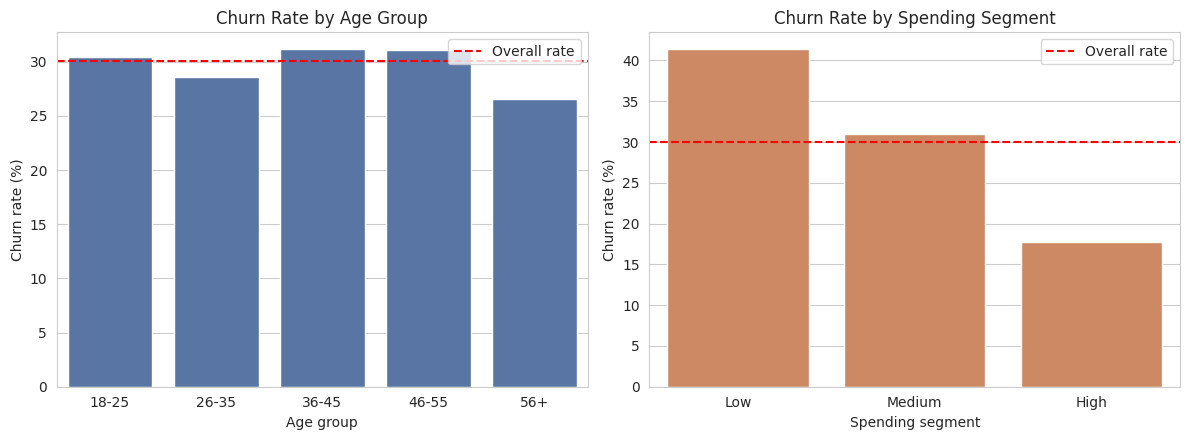

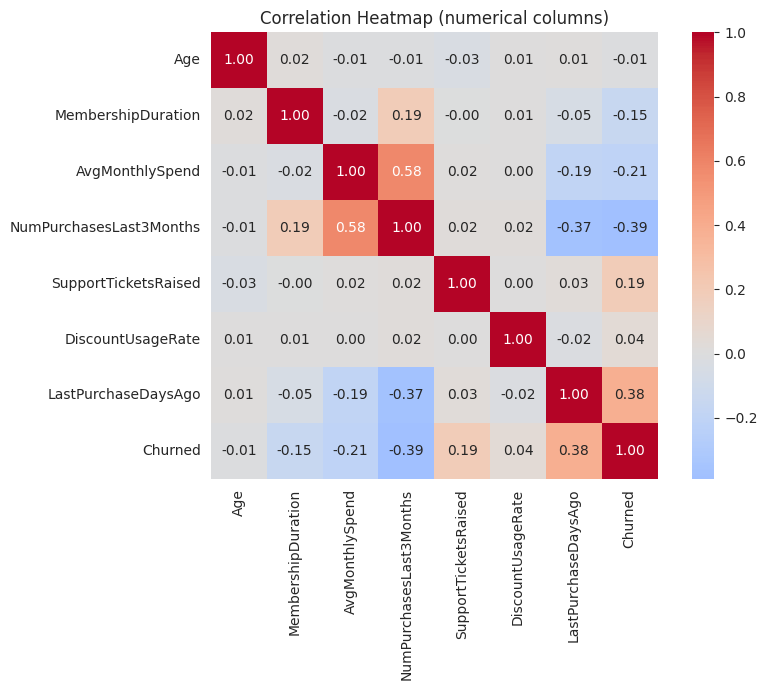

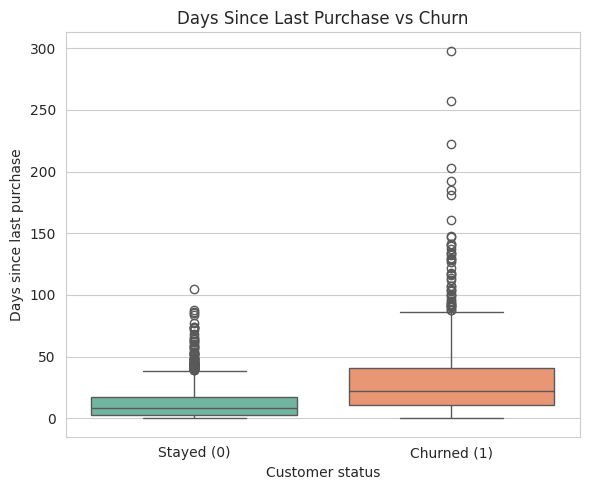


STEP 4: TRAINING THE RANDOM FOREST MODEL
Training rows: 1600 | Test rows: 400
Model trained successfully.

Test-set performance:
  Accuracy : 0.757   (share of all predictions that are right)
  Precision: 0.573   (of predicted churners, how many really churned)
  Recall   : 0.750   (of real churners, how many we caught)
  F1-score : 0.650   (balance of precision and recall)

Confusion matrix (rows = actual, columns = predicted):
                Pred Stayed  Pred Churned
Actual Stayed           213            67
Actual Churned           30            90

Classification report:
              precision    recall  f1-score   support

      Stayed       0.88      0.76      0.81       280
     Churned       0.57      0.75      0.65       120

    accuracy                           0.76       400
   macro avg       0.72      0.76      0.73       400
weighted avg       0.79      0.76      0.77       400



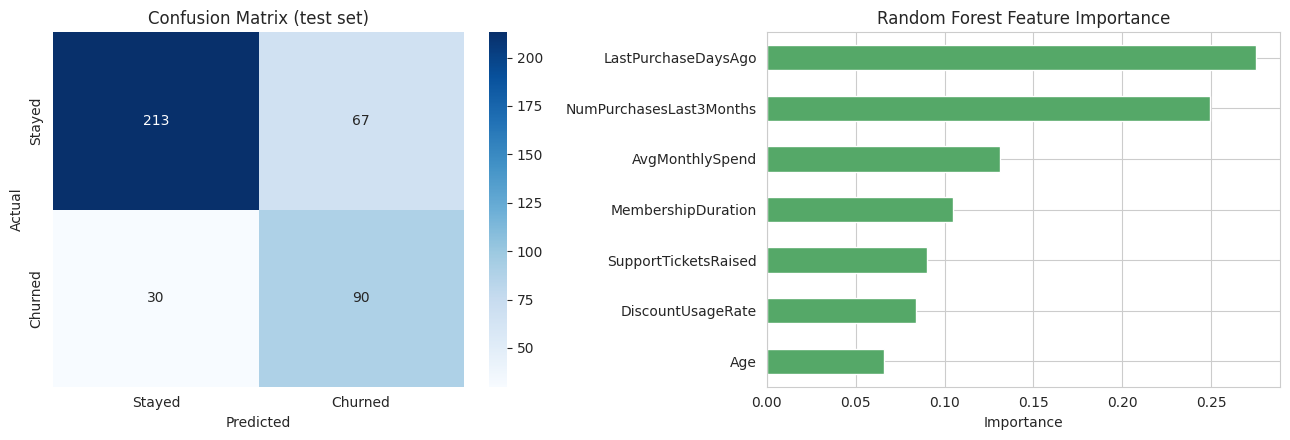

Saved trained model -> churn_model.joblib

STEP 5: PREDICTION EXAMPLES

Example 1 - Disengaged customer (few purchases, long silence, many tickets):
  Predicted status : Churn
  Churn probability: 96.3%
  Risk level       : High

Example 2 - Loyal customer (frequent buyer, recent purchase, no tickets):
  Predicted status : Stay
  Churn probability: 1.5%
  Risk level       : Low

Example 3 - Invalid input (discount rate must be between 0 and 1):
  Invalid input -> DiscountUsageRate must be between 0 and 1 (got 7.0).

All done! Files created: customer_churn_data.csv, churn_model.joblib
(Find them in the Colab Files panel on the left; right-click to download.)


In [2]:
# =====================================================================
#  CUSTOMER CHURN ANALYSIS & PREDICTION SYSTEM  (beginner-friendly)
#  Runs top-to-bottom in ONE Google Colab cell. No uploads, no APIs.
# =====================================================================

# ---------------------------------------------------------------------
# 0. SETUP: install only what is missing, then import libraries
# ---------------------------------------------------------------------
import sys, subprocess, importlib

def ensure_package(pip_name, import_name=None):
    """Install a package only if it cannot be imported (Colab has most already)."""
    try:
        importlib.import_module(import_name or pip_name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

for pip_name, import_name in [("numpy", None), ("pandas", None), ("matplotlib", None),
                              ("seaborn", None), ("scikit-learn", "sklearn"), ("joblib", None)]:
    ensure_package(pip_name, import_name)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

SEED = 42                      # fixed seed -> same results every run
N_CUSTOMERS = 2005
rng = np.random.default_rng(SEED)
sns.set_style("whitegrid")

# Columns used by the model (CustomerID and Churned are deliberately NOT here)
FEATURES = ["Age", "MembershipDuration", "AvgMonthlySpend", "NumPurchasesLast3Months",
            "SupportTicketsRaised", "DiscountUsageRate", "LastPurchaseDaysAgo"]
TARGET = "Churned"

print("=" * 70)
print("STEP 1: GENERATING SYNTHETIC CUSTOMER DATA")
print("=" * 70)

# ---------------------------------------------------------------------
# 1. GENERATE A REALISTIC SYNTHETIC DATASET (2,000 customers)
# ---------------------------------------------------------------------
customer_id = [f"CUST{i:04d}" for i in range(1, N_CUSTOMERS + 1)]
age = np.clip(rng.normal(38, 12, N_CUSTOMERS), 18, 75).round()
membership = np.clip(rng.exponential(24, N_CUSTOMERS) + 1, 1, 120).round()   # months
spend = np.clip(rng.lognormal(np.log(60), 0.5, N_CUSTOMERS), 5, 500).round(2)  # $/month

# Customers who spend more / stay longer tend to buy more often
purchase_rate = np.clip(1 + spend / 20 + membership / 40, 0.5, 15)
purchases = np.clip(rng.poisson(purchase_rate), 0, 30)

tickets = np.clip(rng.poisson(1.2, N_CUSTOMERS), 0, 10)
discount_rate = rng.beta(2, 5, N_CUSTOMERS).round(3)                           # 0 to 1

# More purchases -> bought more recently (fewer days since last purchase)
days_since = np.clip(rng.exponential(90 / (1 + purchases)), 0, 365).round()

def zscore(x):
    return (x - x.mean()) / x.std()

# Churn "recipe": fewer purchases, more days since last purchase and more
# support tickets INCREASE the chance of churn. Longer membership lowers it.
logit = (-1.2
         - 0.9 * zscore(purchases)
         + 0.9 * zscore(days_since)
         + 0.6 * zscore(tickets)
         - 0.3 * zscore(membership)
         + 0.2 * zscore(discount_rate)
         - 0.1 * zscore(spend))
churn_prob = 1 / (1 + np.exp(-logit))              # sigmoid -> probability 0..1
churned = (rng.random(N_CUSTOMERS) < churn_prob).astype(int)

df_raw = pd.DataFrame({
    "CustomerID": customer_id, "Age": age, "MembershipDuration": membership,
    "AvgMonthlySpend": spend, "NumPurchasesLast3Months": purchases,
    "SupportTicketsRaised": tickets, "DiscountUsageRate": discount_rate,
    "LastPurchaseDaysAgo": days_since, "Churned": churned,
})

# ---- Make the data "messy" on purpose, like real company data -------
# (so that the cleaning step in Step 2 has real work to do)
dirty = df_raw.copy()
num_cols = FEATURES
dirty[num_cols] = dirty[num_cols].astype(float)     # allows NaN in every column
dirty["Churned"] = dirty["Churned"].astype(object)  # allows text labels

# (a) missing values (~2% per column)
for col in ["Age", "AvgMonthlySpend", "SupportTicketsRaised",
            "LastPurchaseDaysAgo", "DiscountUsageRate", "MembershipDuration"]:
    idx = rng.choice(N_CUSTOMERS, size=int(0.02 * N_CUSTOMERS), replace=False)
    dirty.loc[idx, col] = np.nan

# (b) invalid values (impossible ages, negative spend, rate above 100%, ...)
bad = rng.choice(N_CUSTOMERS, size=40, replace=False)
dirty.loc[bad[:8], "Age"] = rng.choice([-5, 0, 150, 200], size=8)
dirty.loc[bad[8:16], "AvgMonthlySpend"] = -rng.uniform(1, 100, size=8)
dirty.loc[bad[16:24], "DiscountUsageRate"] = rng.choice([1.5, 5.0, -0.2], size=8)
dirty.loc[bad[24:32], "LastPurchaseDaysAgo"] = -rng.integers(1, 50, size=8)
dirty.loc[bad[32:40], "NumPurchasesLast3Months"] = -rng.integers(1, 5, size=8)

# (c) inconsistent churn labels (Yes / no / 1 / "Y" ...) in ~15% of rows
label_variants = {1: ["Yes", "yes ", " YES", "Y", "1", "churned"],
                  0: ["No", "no", "NO ", "N", "0", "retained"]}
for i in rng.choice(N_CUSTOMERS, size=int(0.15 * N_CUSTOMERS), replace=False):
    dirty.at[i, "Churned"] = str(rng.choice(label_variants[int(df_raw.at[i, "Churned"])]))
# a few rows with an unusable label
dirty.loc[rng.choice(N_CUSTOMERS, size=5, replace=False), "Churned"] = "unknown"

# (d) duplicated customers (some with messy ID formatting)
dups = dirty.sample(25, random_state=SEED).copy()
dups.loc[dups.index[:10], "CustomerID"] = (" " + dups.loc[dups.index[:10], "CustomerID"].str.lower() + " ")
dirty = pd.concat([dirty, dups], ignore_index=True)

print(f"Raw (messy) dataset created: {dirty.shape[0]} rows x {dirty.shape[1]} columns")
print(dirty.head())

# ---------------------------------------------------------------------
# 2. DATA CLEANING
# ---------------------------------------------------------------------
print("\n" + "=" * 70)
print("STEP 2: CLEANING THE DATA")
print("=" * 70)

df = dirty.copy()
rows_start = len(df)
df.columns = df.columns.str.strip()

# 2a. Fix inconsistent CustomerIDs (spaces / lowercase) and remove duplicates
df["CustomerID"] = df["CustomerID"].astype(str).str.strip().str.upper()
before = len(df)
df = df.drop_duplicates(subset="CustomerID", keep="first")
print(f"Duplicate CustomerIDs removed : {before - len(df)}")

# 2b. Standardise the Churned labels to 0 / 1
label_map = {"1": 1, "yes": 1, "y": 1, "true": 1, "churned": 1,
             "0": 0, "no": 0, "n": 0, "false": 0, "retained": 0}
df["Churned"] = df["Churned"].astype(str).str.strip().str.lower().map(label_map)
before = len(df)
df = df.dropna(subset=["Churned"])      # we never invent a target label
df["Churned"] = df["Churned"].astype(int)
print(f"Rows dropped (unusable label)  : {before - len(df)}")

# 2c. Make sure numeric columns are numeric
for col in FEATURES:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 2d. Invalid ranges -> mark as missing (NaN)
VALID_RANGES = {"Age": (18, 100), "MembershipDuration": (0, 600),
                "AvgMonthlySpend": (0, 5000), "NumPurchasesLast3Months": (0, 100),
                "SupportTicketsRaised": (0, 50), "DiscountUsageRate": (0, 1),
                "LastPurchaseDaysAgo": (0, 3650)}
invalid_total = 0
for col, (lo, hi) in VALID_RANGES.items():
    mask = (df[col] < lo) | (df[col] > hi)
    invalid_total += int(mask.sum())
    df.loc[mask, col] = np.nan
print(f"Invalid values set to missing  : {invalid_total}")

# 2e. Missing values
print("\nMissing values per column (before filling):")
print(df[FEATURES].isna().sum().to_string())

# df_model keeps the NaNs: the model pipeline fills them using TRAINING data
# only (this prevents leakage from the test set).
df_model = df.copy()

# df_clean is a fully filled copy (median) used for analysis and saved to CSV.
df_clean = df.copy()
for col in FEATURES:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())
for col in ["Age", "MembershipDuration", "NumPurchasesLast3Months",
            "SupportTicketsRaised", "LastPurchaseDaysAgo"]:
    df_clean[col] = df_clean[col].round().astype(int)   # whole numbers
df_clean["AvgMonthlySpend"] = df_clean["AvgMonthlySpend"].round(2)
df_clean["DiscountUsageRate"] = df_clean["DiscountUsageRate"].round(3)
df_clean = df_clean.reset_index(drop=True)
df_model = df_model.reset_index(drop=True)

print(f"\nRows: {rows_start} (raw) -> {len(df_clean)} (clean)")
print("Missing values left in df_clean:", int(df_clean.isna().sum().sum()))

# ---------------------------------------------------------------------
# 3. SAVE THE CLEANED DATASET
# ---------------------------------------------------------------------
df_clean.to_csv("customer_churn_data.csv", index=False)
print("Saved cleaned dataset -> customer_churn_data.csv")

# ---------------------------------------------------------------------
# 4. EXPLORATORY ANALYSIS
# ---------------------------------------------------------------------
print("\n" + "=" * 70)
print("STEP 3: CHURN ANALYSIS")
print("=" * 70)

# 4a. Overall churn rate
overall_rate = df_clean[TARGET].mean() * 100
print(f"Overall churn rate: {overall_rate:.1f}%  "
      f"({df_clean[TARGET].sum()} of {len(df_clean)} customers churned)")

# 4b. Churn by age group and by spending segment
df_clean["AgeGroup"] = pd.cut(df_clean["Age"], bins=[17, 25, 35, 45, 55, 100],
                              labels=["18-25", "26-35", "36-45", "46-55", "56+"])
df_clean["SpendSegment"] = pd.qcut(df_clean["AvgMonthlySpend"], q=3,
                                   labels=["Low", "Medium", "High"])

churn_by_age = df_clean.groupby("AgeGroup", observed=True)[TARGET].mean() * 100
churn_by_spend = df_clean.groupby("SpendSegment", observed=True)[TARGET].mean() * 100
print("\nChurn rate (%) by age group:")
print(churn_by_age.round(1).to_string())
print("\nChurn rate (%) by spending segment:")
print(churn_by_spend.round(1).to_string())

# 4c. Top 3 factors associated with churn (correlation with Churned)
corr_with_churn = df_clean[FEATURES + [TARGET]].corr()[TARGET].drop(TARGET)
top3 = corr_with_churn.abs().sort_values(ascending=False).head(3).index
print("\nTop 3 factors associated with churn:")
for rank, feat in enumerate(top3, start=1):
    r = corr_with_churn[feat]
    direction = "higher value -> MORE churn" if r > 0 else "higher value -> LESS churn"
    print(f"  {rank}. {feat:<26} correlation = {r:+.3f}  ({direction})")

# ---------------------------------------------------------------------
# 5. VISUALISATIONS
# ---------------------------------------------------------------------
# Plot 1: churn-rate bar charts
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(x=churn_by_age.index.astype(str), y=churn_by_age.values,
            ax=axes[0], color="#4C72B0")
axes[0].set_title("Churn Rate by Age Group")
axes[0].set_xlabel("Age group"); axes[0].set_ylabel("Churn rate (%)")
sns.barplot(x=churn_by_spend.index.astype(str), y=churn_by_spend.values,
            ax=axes[1], color="#DD8452")
axes[1].set_title("Churn Rate by Spending Segment")
axes[1].set_xlabel("Spending segment"); axes[1].set_ylabel("Churn rate (%)")
for ax in axes:
    ax.axhline(overall_rate, color="red", linestyle="--", label="Overall rate")
    ax.legend()
plt.tight_layout(); plt.show()

# Plot 2: correlation heatmap of numerical columns
plt.figure(figsize=(9, 7))
sns.heatmap(df_clean[FEATURES + [TARGET]].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap (numerical columns)")
plt.tight_layout(); plt.show()

# Plot 3: box plot of LastPurchaseDaysAgo by Churned
plt.figure(figsize=(6, 5))
sns.boxplot(x=df_clean[TARGET].map({0: "Stayed (0)", 1: "Churned (1)"}),
            y=df_clean["LastPurchaseDaysAgo"], hue=df_clean[TARGET].map({0: "Stayed (0)", 1: "Churned (1)"}),
            palette="Set2", legend=False)
plt.title("Days Since Last Purchase vs Churn")
plt.xlabel("Customer status"); plt.ylabel("Days since last purchase")
plt.tight_layout(); plt.show()

# ---------------------------------------------------------------------
# 6. TRAIN THE RANDOM FOREST MODEL (with a leakage-safe pipeline)
# ---------------------------------------------------------------------
print("\n" + "=" * 70)
print("STEP 4: TRAINING THE RANDOM FOREST MODEL")
print("=" * 70)

# X = inputs the model may see. y = the answer we want to predict.
# CustomerID is an identifier (not a real signal) and is excluded.
X = df_model[FEATURES]
y = df_model[TARGET]

# 80/20 split BEFORE any learning from the data. stratify keeps the same
# churn proportion in both train and test sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y)
print(f"Training rows: {len(X_train)} | Test rows: {len(X_test)}")

# Pipeline = preprocessing + model in one object.
# The imputer learns medians from TRAINING data only (no leakage).
# Random Forests do not need feature scaling, so we skip a scaler.
preprocess = ColumnTransformer([("fill_missing", SimpleImputer(strategy="median"), FEATURES)])
churn_model = Pipeline([
    ("preprocess", preprocess),
    ("rf", RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=5,
                                  class_weight="balanced", random_state=SEED, n_jobs=-1)),
])
churn_model.fit(X_train, y_train)
print("Model trained successfully.")

# ---------------------------------------------------------------------
# 7. EVALUATE ON THE UNSEEN TEST SET
# ---------------------------------------------------------------------
y_pred = churn_model.predict(X_test)

print("\nTest-set performance:")
print(f"  Accuracy : {accuracy_score(y_test, y_pred):.3f}   (share of all predictions that are right)")
print(f"  Precision: {precision_score(y_test, y_pred):.3f}   (of predicted churners, how many really churned)")
print(f"  Recall   : {recall_score(y_test, y_pred):.3f}   (of real churners, how many we caught)")
print(f"  F1-score : {f1_score(y_test, y_pred):.3f}   (balance of precision and recall)")

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(cm, index=["Actual Stayed", "Actual Churned"],
                   columns=["Pred Stayed", "Pred Churned"]).to_string())

print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))

# Extra plots: confusion matrix and feature importance
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Stayed", "Churned"], yticklabels=["Stayed", "Churned"])
axes[0].set_title("Confusion Matrix (test set)")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

importances = pd.Series(churn_model.named_steps["rf"].feature_importances_,
                        index=FEATURES).sort_values()
importances.plot(kind="barh", ax=axes[1], color="#55A868")
axes[1].set_title("Random Forest Feature Importance")
axes[1].set_xlabel("Importance")
plt.tight_layout(); plt.show()

# ---------------------------------------------------------------------
# 8. SAVE THE MODEL
# ---------------------------------------------------------------------
joblib.dump(churn_model, "churn_model.joblib")
print("Saved trained model -> churn_model.joblib")
loaded_model = joblib.load("churn_model.joblib")   # check that it reloads

# ---------------------------------------------------------------------
# 9. PREDICTION FUNCTION (with input validation)
# ---------------------------------------------------------------------
# name -> (column name, minimum, maximum, must be a whole number?)
INPUT_RULES = {
    "age":                         ("Age", 18, 100, True),
    "membership_duration":         ("MembershipDuration", 0, 600, False),
    "avg_monthly_spend":           ("AvgMonthlySpend", 0, 5000, False),
    "num_purchases_last_3_months": ("NumPurchasesLast3Months", 0, 100, True),
    "support_tickets_raised":      ("SupportTicketsRaised", 0, 50, True),
    "discount_usage_rate":         ("DiscountUsageRate", 0, 1, False),
    "last_purchase_days_ago":      ("LastPurchaseDaysAgo", 0, 3650, False),
}

def _validate_single(key, value):
    """Check ONE input. Returns it as a float or raises a clear ValueError."""
    col, lo, hi, whole = INPUT_RULES[key]
    if value is None or isinstance(value, bool):
        raise ValueError(f"{col} must be a number.")
    try:
        number = float(value)
    except (TypeError, ValueError):
        raise ValueError(f"{col} must be a number (got {value!r}).")
    if not np.isfinite(number):
        raise ValueError(f"{col} must be a finite number.")
    if not lo <= number <= hi:
        raise ValueError(f"{col} must be between {lo} and {hi} (got {number}).")
    if whole and number != int(number):
        raise ValueError(f"{col} must be a whole number (got {number}).")
    return number

def predict_churn(age, membership_duration, avg_monthly_spend,
                  num_purchases_last_3_months, support_tickets_raised,
                  discount_usage_rate, last_purchase_days_ago, model=None):
    """
    Predict whether ONE customer will churn.
    Returns a dictionary with the predicted status and churn probability.
    Raises ValueError if any input is invalid.
    """
    if model is None:
        model = loaded_model
    raw = dict(age=age, membership_duration=membership_duration,
               avg_monthly_spend=avg_monthly_spend,
               num_purchases_last_3_months=num_purchases_last_3_months,
               support_tickets_raised=support_tickets_raised,
               discount_usage_rate=discount_usage_rate,
               last_purchase_days_ago=last_purchase_days_ago)
    clean = {key: _validate_single(key, val) for key, val in raw.items()}

    # Build a one-row table with the SAME column names/order used in training
    row = pd.DataFrame([[clean["age"], clean["membership_duration"],
                         clean["avg_monthly_spend"], clean["num_purchases_last_3_months"],
                         clean["support_tickets_raised"], clean["discount_usage_rate"],
                         clean["last_purchase_days_ago"]]], columns=FEATURES)

    churn_index = list(model.classes_).index(1)
    prob = float(model.predict_proba(row)[0][churn_index])
    risk = "High" if prob >= 0.65 else "Medium" if prob >= 0.35 else "Low"
    return {"prediction": "Churn" if prob >= 0.5 else "Stay",
            "churn_probability": round(prob, 3), "risk_level": risk}

def show_prediction(**customer):
    """Pretty-print a prediction; shows a friendly message if input is invalid."""
    try:
        result = predict_churn(**customer)
        print(f"  Predicted status : {result['prediction']}")
        print(f"  Churn probability: {result['churn_probability']:.1%}")
        print(f"  Risk level       : {result['risk_level']}")
    except ValueError as err:
        print(f"  Invalid input -> {err}")

def predict_churn_interactive():
    """
    OPTIONAL: asks you to type each value (with validation, re-asking on mistakes).
    Not called automatically, because input() can block a Colab run.
    To use it, set USE_INTERACTIVE_INPUT = True below and re-run.
    """
    questions = [("age", "Age (18-100)"),
                 ("membership_duration", "MembershipDuration in months (0-600)"),
                 ("avg_monthly_spend", "AvgMonthlySpend (0-5000)"),
                 ("num_purchases_last_3_months", "NumPurchasesLast3Months (0-100)"),
                 ("support_tickets_raised", "SupportTicketsRaised (0-50)"),
                 ("discount_usage_rate", "DiscountUsageRate (0.0-1.0)"),
                 ("last_purchase_days_ago", "LastPurchaseDaysAgo (0-3650)")]
    answers = {}
    for key, label in questions:
        while True:
            try:
                answers[key] = _validate_single(key, input(f"{label}: "))
                break
            except ValueError as err:
                print(f"  Invalid input -> {err} Please try again.")
    show_prediction(**answers)

# ---------------------------------------------------------------------
# 10. PREDICTION EXAMPLES (run automatically, no typing needed)
# ---------------------------------------------------------------------
print("\n" + "=" * 70)
print("STEP 5: PREDICTION EXAMPLES")
print("=" * 70)

print("\nExample 1 - Disengaged customer (few purchases, long silence, many tickets):")
show_prediction(age=29, membership_duration=6, avg_monthly_spend=25.0,
                num_purchases_last_3_months=1, support_tickets_raised=5,
                discount_usage_rate=0.6, last_purchase_days_ago=150)

print("\nExample 2 - Loyal customer (frequent buyer, recent purchase, no tickets):")
show_prediction(age=45, membership_duration=48, avg_monthly_spend=120.0,
                num_purchases_last_3_months=12, support_tickets_raised=0,
                discount_usage_rate=0.1, last_purchase_days_ago=5)

print("\nExample 3 - Invalid input (discount rate must be between 0 and 1):")
show_prediction(age=30, membership_duration=12, avg_monthly_spend=50.0,
                num_purchases_last_3_months=3, support_tickets_raised=1,
                discount_usage_rate=7, last_purchase_days_ago=40)

USE_INTERACTIVE_INPUT = False      # change to True if you want to type values
if USE_INTERACTIVE_INPUT:
    predict_churn_interactive()

print("\nAll done! Files created: customer_churn_data.csv, churn_model.joblib")
print("(Find them in the Colab Files panel on the left; right-click to download.)")